In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import openpyxl

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, log_loss

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import KFold, cross_val_score

## Regression - Facebook page dataset

https://archive.ics.uci.edu/dataset/368/facebook+metrics 

In [96]:
#loading the dataset
facebook = pd.read_csv("data_lab1/facebook+metrics/dataset_Facebook.csv", sep = ";")
facebook

,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,109,159,3078,1640,119,4,79.0,17.0,100
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,1361,1674,11710,6112,1108,5,130.0,29.0,164
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,113,154,2812,1503,132,0,66.0,14.0,80
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,790,1119,61027,32048,1386,58,1572.0,147.0,1777
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,410,580,6228,3200,396,19,325.0,49.0,393
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,85093,Photo,3,1,7,2,0.0,4684,7536,733,708,985,4750,2876,392,5,53.0,26.0,84
496,81370,Photo,2,1,5,8,0.0,3480,6229,537,508,687,3961,2104,301,0,53.0,22.0,75
497,81370,Photo,1,1,5,2,0.0,3778,7216,625,572,795,4742,2388,363,4,93.0,18.0,115
498,81370,Photo,3,1,4,11,0.0,4156,7564,626,574,832,4534,2452,370,7,91.0,38.0,136


In [97]:
# veryfing if there is any missing value in the dataset - there is very few
facebook.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                                                               Non-Null Count  Dtype  
---  ------                                                               --------------  -----  
 0   Page total likes                                                     500 non-null    int64  
 1   Type                                                                 500 non-null    object 
 2   Category                                                             500 non-null    int64  
 3   Post Month                                                           500 non-null    int64  
 4   Post Weekday                                                         500 non-null    int64  
 5   Post Hour                                                            500 non-null    int64  
 6   Paid                                                                 499 non-null    float64
 7   Lifetime

In [98]:
#correcting missing values in the dataset
facebook[facebook['Paid'].isna()] = 0

In [99]:
#dropping the columns for comments, likes and shares as total interactions is the sum of these 3
facebook.drop(["like","comment", "share"], axis=1, inplace=True)

In [100]:
#checking for general statistics
facebook.describe().T

,count,mean,std,min,25%,50%,75%,max
Page total likes,500.0,123031.436,17078.841206,0.0,112676.00,129600.0,136393.00,139441.0
Category,500.0,1.876,0.856792,0.0,1.00,2.0,3.00,3.0
Post Month,500.0,7.036,3.311894,0.0,4.00,7.0,10.00,12.0
Post Weekday,500.0,4.142,2.039155,0.0,2.00,4.0,6.00,7.0
Post Hour,500.0,7.832,4.379284,0.0,3.00,9.0,11.00,23.0
Paid,500.0,0.278,0.448462,0.0,0.00,0.0,1.00,1.0
Lifetime Post Total Reach,500.0,13894.984,22745.144326,0.0,3293.00,5281.0,13168.00,180480.0
Lifetime Post Total Impressions,500.0,29571.364,76808.180675,0.0,5676.25,9051.0,22085.50,1110282.0
Lifetime Engaged Users,500.0,919.216,985.748187,0.0,392.75,625.5,1062.00,11452.0
Lifetime Post Consumers,500.0,797.724,883.142869,0.0,330.75,551.5,955.50,11328.0


In [101]:
#creating the dataset to predict the "Page total likes" variable and creating the target 
X = facebook.drop(["Page total likes", "Type"], axis=1)
y = facebook["Page total likes"]


In [102]:
#creating a pool for training the model and a validation set with 20% of the whole data 
X_train_pool, X_val, y_train_pool, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [103]:
#creating a list of different training set sizes to test the model
sizes = list(range(10, 101, 30))
ntrials = 6 #defining a number of trials to run each training set size

In [104]:
train_mses = []
val_mses = []

for s in sizes:
    trial_tmse = []
    trial_vmse = []
    for n in range(ntrials):
        #split the training pool into a training set of size s
        X_train, _, y_train, _ = train_test_split(X_train_pool, y_train_pool, train_size=s, random_state=n)
        model = LinearRegression()
        model.fit(X_train, y_train)    #fitting a linear model on the training data

        #predting the training and validation data
        train_pred = model.predict(X_train)
        val_pred = model.predict(X_val)
        
        mse_train = mean_squared_error(y_train, train_pred)
        mse_val = mean_squared_error(y_val, val_pred)

        trial_tmse.append(mse_train)
        trial_vmse.append(mse_val)

    #printing the avg mse for each training set size   
    print(f"Sample Size {s}: \n Training Mean Squared Error = {np.mean(trial_tmse):.3f} \n Validation Mean Squared Error = {np.mean(trial_vmse):.3f}")
    print("\n")

    #appending the avg mse for each training size so we can later plot them
    train_mses.append(np.mean(trial_tmse))
    val_mses.append(np.mean(trial_vmse))

Sample Size 10: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 17599564663920.098


Sample Size 40: 
 Training Mean Squared Error = 14401379.178 
 Validation Mean Squared Error = 1604304637.041


Sample Size 70: 
 Training Mean Squared Error = 19351359.426 
 Validation Mean Squared Error = 147451647.804


Sample Size 100: 
 Training Mean Squared Error = 41004817.800 
 Validation Mean Squared Error = 417693517.105




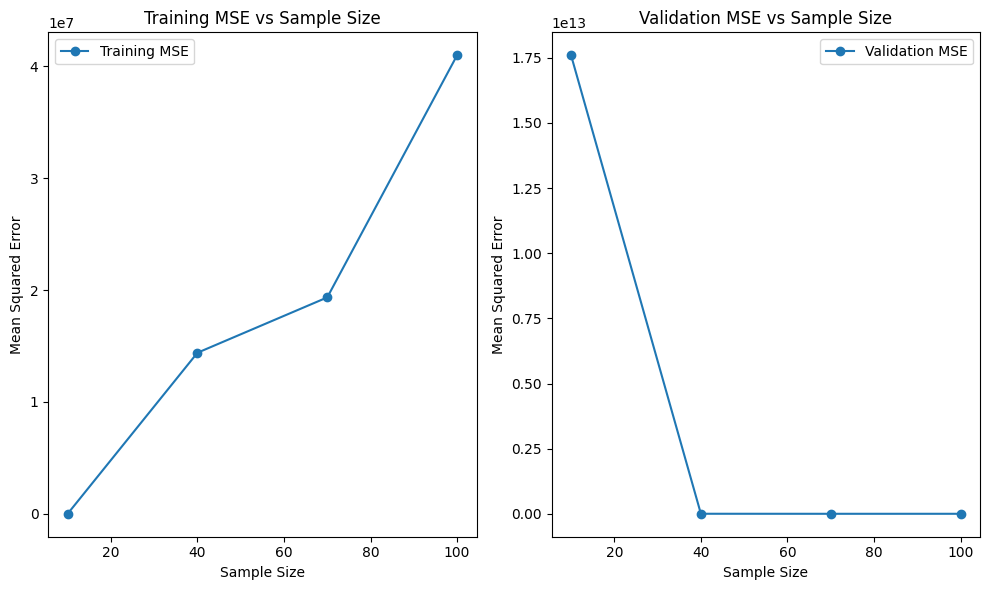

In [105]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, train_mses, label='Training MSE', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Mean Squared Error')
ax1.set_title('Training MSE vs Sample Size')
ax1.legend()

ax2.plot(sizes, val_mses, label='Validation MSE', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Mean Squared Error')
ax2.set_title('Validation MSE vs Sample Size')
ax2.legend()

plt.tight_layout()
plt.show()

## Quadratic regression - Facebook page dataset

In [109]:
qtrain_mses = []
qval_mses = []

for s in sizes:
    qtrial_tmse = []
    qtrial_vmse = []
    for n in range(ntrials):
        #split the training pool into a training set of size s
        X_train, _, y_train, _ = train_test_split(X_train_pool, y_train_pool, train_size=s, random_state=n)
        qmodel = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
        qmodel.fit(X_train, y_train)    #fitting a linear model on the training data

        #predting the training and validation data
        qtrain_pred = qmodel.predict(X_train)
        qval_pred = qmodel.predict(X_val)
        
        qmse_train = mean_squared_error(y_train, qtrain_pred)
        qmse_val = mean_squared_error(y_val, qval_pred)

        qtrial_tmse.append(qmse_train)
        qtrial_vmse.append(qmse_val)

    #printing the avg mse for each training set size   
    print(f"Sample Size {s}: \n Training Mean Squared Error = {np.mean(qtrial_tmse):.3f} \n Validation Mean Squared Error = {np.mean(qtrial_vmse):.3f}")
    print("\n")

    #appending the avg mse for each training size so we can later plot them
    qtrain_mses.append(np.mean(qtrial_tmse))
    qval_mses.append(np.mean(qtrial_vmse))

Sample Size 10: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 628482564311561216.000


Sample Size 40: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 388720314231579840.000


Sample Size 70: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 49864619828041272.000


Sample Size 100: 
 Training Mean Squared Error = 0.000 
 Validation Mean Squared Error = 88442815954411440.000




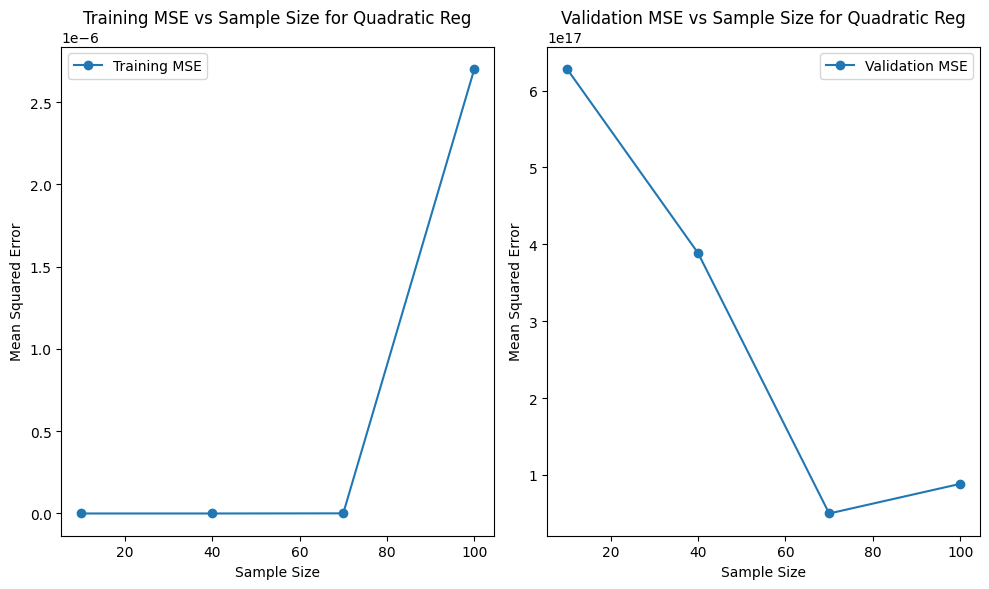

In [110]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, qtrain_mses, label='Training MSE', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Mean Squared Error')
ax1.set_title('Training MSE vs Sample Size for Quadratic Reg')
ax1.legend()

ax2.plot(sizes, qval_mses, label='Validation MSE', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Mean Squared Error')
ax2.set_title('Validation MSE vs Sample Size for Quadratic Reg')
ax2.legend()

plt.tight_layout()
plt.show()

## Cross-validation - Facebook page dataset

In [111]:
lscores = cross_val_score(model, X_train_pool, y_train_pool, cv=5, scoring='neg_mean_squared_error')

qscores = cross_val_score(qmodel, X_train_pool, y_train_pool, cv=5, scoring='neg_mean_squared_error')

lin_cv_mse = -np.mean(lscores)
quad_cv_mse = -np.mean(qscores)

print(f"Linear Regression Cross-Validation MSE: {lin_cv_mse:.3f}")
print(f"Quadratic Regression Cross-Validation MSE: {quad_cv_mse:.3f}")

Linear Regression Cross-Validation MSE: 60757829.268
Quadratic Regression Cross-Validation MSE: 3647738845.355


According to the cross-validation, the linear regression is a better model for the Facebook page dataset.

## Regression - News popularity in social media dataset

https://archive.ics.uci.edu/dataset/432/news+popularity+in+multiple+social+media+platforms

In [ ]:
# data preparation
# sample training sets of 10,20,30,... I WOULD MAYBE DO BIGGER SIZES BCOS OF THE DATASET SIZE

In [ ]:
# apply linear regression

In [ ]:
# calculate mse score

## Quadratic regression - News popularity on social media dataset

In [ ]:
#do the same as in regression but use logistic regression and logistic loss function

## Classification - Wine dataset

https://archive.ics.uci.edu/dataset/320/student+performance

In [126]:
mat = pd.read_csv("data_lab1/student/student-mat.csv", sep=";")
por = pd.read_csv("data_lab1/student/student-por.csv", sep=";")

performance = pd.concat([mat, por], axis=0)
performance.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [127]:
performance.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1044 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      1044 non-null   object
 1   sex         1044 non-null   object
 2   age         1044 non-null   int64 
 3   address     1044 non-null   object
 4   famsize     1044 non-null   object
 5   Pstatus     1044 non-null   object
 6   Medu        1044 non-null   int64 
 7   Fedu        1044 non-null   int64 
 8   Mjob        1044 non-null   object
 9   Fjob        1044 non-null   object
 10  reason      1044 non-null   object
 11  guardian    1044 non-null   object
 12  traveltime  1044 non-null   int64 
 13  studytime   1044 non-null   int64 
 14  failures    1044 non-null   int64 
 15  schoolsup   1044 non-null   object
 16  famsup      1044 non-null   object
 17  paid        1044 non-null   object
 18  activities  1044 non-null   object
 19  nursery     1044 non-null   object
 20  higher      10

In [128]:
performance.describe().T

,count,mean,std,min,25%,50%,75%,max
age,1044.0,16.726054,1.239975,15.0,16.0,17.0,18.0,22.0
Medu,1044.0,2.603448,1.124907,0.0,2.0,3.0,4.0,4.0
Fedu,1044.0,2.387931,1.099938,0.0,1.0,2.0,3.0,4.0
traveltime,1044.0,1.522989,0.731727,1.0,1.0,1.0,2.0,4.0
studytime,1044.0,1.970307,0.834353,1.0,1.0,2.0,2.0,4.0
failures,1044.0,0.264368,0.656142,0.0,0.0,0.0,0.0,3.0
famrel,1044.0,3.935824,0.933401,1.0,4.0,4.0,5.0,5.0
freetime,1044.0,3.201149,1.031507,1.0,3.0,3.0,4.0,5.0
goout,1044.0,3.156130,1.152575,1.0,2.0,3.0,4.0,5.0
Dalc,1044.0,1.494253,0.911714,1.0,1.0,1.0,2.0,5.0


In [129]:
performance.describe(include=["O"]).T

,count,unique,top,freq
school,1044,2,GP,772
sex,1044,2,F,591
address,1044,2,U,759
famsize,1044,2,GT3,738
Pstatus,1044,2,T,923
Mjob,1044,5,other,399
Fjob,1044,5,other,584
reason,1044,4,course,430
guardian,1044,3,mother,728
schoolsup,1044,2,no,925


In [ ]:
map = {"yes":1, "no":0}

cols = ['schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

performance[cols] = performance[cols].apply

## Classification - Online Retail dataset

https://archive.ics.uci.edu/dataset/352/online+retail

In [112]:
online = pd.read_excel("data_lab1/online+retail/Online Retail.xlsx")
online.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [113]:
online.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [114]:
online.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [115]:
#creating a new var to predict from the dataset: whether the customer is from the UK or not
online["UK_based"] = online["Country"].apply(lambda x: 1 if x =="United Kingdom" else 0)

#creating a new var to know whether the order was cancelled or not: if the invoice number starts with a "C"
online["Cancelled"] = online["InvoiceNo"].apply(lambda x: 1 if str(x).upper().startswith("C") else 0)

#creating new variables to get information about the invoice date
online["InvoiceDate"] = pd.to_datetime(online["InvoiceDate"]) #first transform into datetime variable

online["Month"] = online["InvoiceDate"].dt.month
online["Day_week"] = online["InvoiceDate"].dt.dayofweek
online["Hour"] = online["InvoiceDate"].dt.hour
online["Weekend"] = online["Day_week"].apply(lambda x: 1 if x >= 5 else 0)

online.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,UK_based,Cancelled,Month,Day_week,Hour,Weekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,1,0,12,2,8,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,1,0,12,2,8,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,1,0,12,2,8,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,1,0,12,2,8,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,1,0,12,2,8,0


In [116]:
X = online.drop(["InvoiceNo", "StockCode", "Description", "InvoiceDate","CustomerID" ,"Country", "UK_based"],axis=1)
y = online["UK_based"]

In [117]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [118]:

lmodel = LogisticRegression()

In [120]:
sizes=list(range(1000, len(X_train), 15000))
repeats= 6
train_losses, val_losses = [], []


for s in sizes:
    tr, va = [], []
    for r in range(repeats):
        X_sample, _, y_sample, _ = train_test_split(
            X_train, y_train, train_size=s, random_state=r, stratify=y_train
        )

        lmodel.fit(X_sample, y_sample)

        val_loss = lmodel.predict_proba(X_test)
        tr.append(log_loss(y_sample, lmodel.predict_proba(X_sample)))
        va.append(log_loss(y_test, val_loss))

    train_losses.append(np.mean(tr))
    val_losses.append(np.mean(va))

c:\Anaconda\envs\ml2\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Anaconda\envs\ml2\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _che

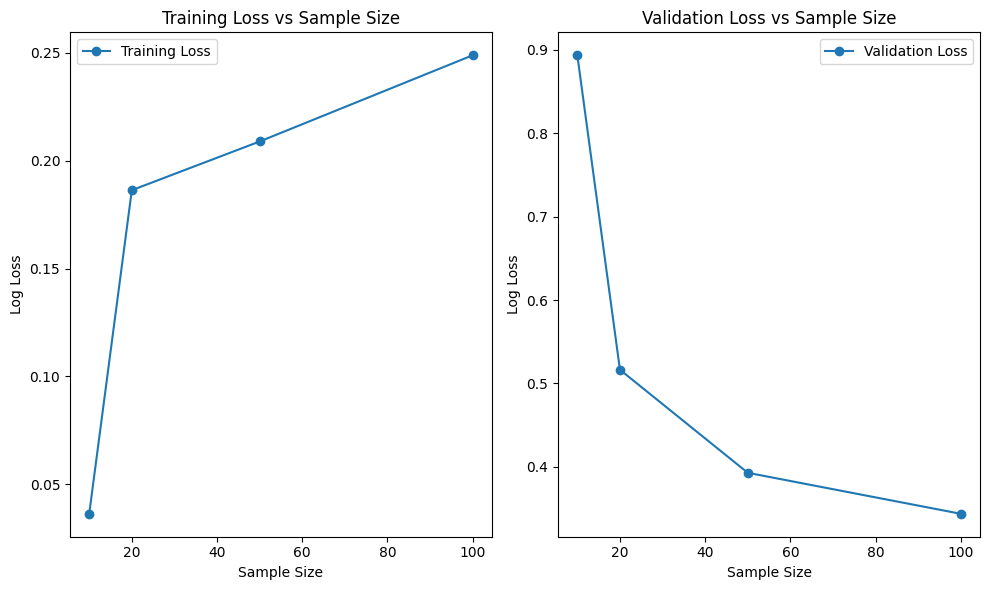

In [ ]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10, 6))

ax1.plot(sizes, train_losses, label='Training Loss', marker='o')
ax1.set_xlabel('Sample Size')
ax1.set_ylabel('Log Loss')
ax1.set_title('Training Loss vs Sample Size')
ax1.legend()

ax2.plot(sizes, val_losses, label='Validation Loss', marker='o')
ax2.set_xlabel('Sample Size')
ax2.set_ylabel('Log Loss')
ax2.set_title('Validation Loss vs Sample Size')
ax2.legend()

plt.tight_layout()
plt.show()

In [92]:
quad_loss = []
quad_val_loss = []
quad_model = make_pipeline(PolynomialFeatures(degree=2), LogisticRegression())

for s in sizes:
    q_tr, q_va = [], []
    for r in range(repeats):
        X_sample, _, y_sample, _ = train_test_split(X_train, y_train, train_size=s, random_state=r, stratify=y_train)
        
        quad_model.fit(X_sample, y_sample)  
        q_val_loss = quad_model.predict_proba(X_test)
        q_tr.append(log_loss(y_sample, quad_model.predict_proba(X_sample)))
        q_va.append(log_loss(y_test, q_val_loss))

    quad_loss.append(np.mean(q_tr))
    quad_val_loss.append(np.mean(q_va))

c:\Anaconda\envs\ml2\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Anaconda\envs\ml2\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _che